# Lab: triagem de mamografias

Notebook de aula da página: https://insper.github.io/ML/pt/2026.2/classes/roc-imbalanced/

Rode as células em ordem. Em cada passo, responda o **Preveja** com a dupla *antes* de rodar. Nas **Simulações**, escreva o experimento na célula vazia; as soluções e a leitura de cada resultado estão na página da aula.

## Passo 1 — carregar e olhar a prevalência

**Preveja.** Microcalcificações são achados raros numa mamografia. Antes de rodar: você espera que elas sejam mais ou menos de 10% das regiões? Com essa prevalência, quanto de acurácia um modelo que nunca sinaliza nada conseguiria?

In [1]:
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_openml

mammo = fetch_openml(data_id=310, as_frame=True)
X = mammo.data                                   # 6 atributos numéricos por região
y = (mammo.target == '1').astype(int)            # o alvo é '-1' (benigno) ou '1' (maligno)
print(X.shape)
print(y.value_counts())
print(f"prevalence: {y.mean():.2%}")

(11183, 6)
class
0    10923
1      260
Name: count, dtype: int64
prevalence: 2.32%


**Resposta.** Bem menos de 10%: só 260 das 11.183 regiões são malignas (prevalência 2,32%). Um modelo que nunca sinaliza nada acertaria 10.923/11.183 = 97,7%.

## Passo 2 — divisão estratificada treino / validação / teste

**Preveja.** Por que estratificar importa mais aqui do que num conjunto equilibrado? Se a validação tiver cerca de 50 casos malignos, quanto de recall vale um único caso?

In [2]:
from sklearn.model_selection import train_test_split

X_tmp, X_test, y_tmp, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=7)
X_train, X_val, y_train, y_val = train_test_split(X_tmp, y_tmp, test_size=0.25,
                                                  stratify=y_tmp, random_state=7)
for name, part in [('train', y_train), ('validation', y_val), ('test', y_test)]:
    print(f"{name:10s} {len(part):5d} rows  {part.sum():3d} malignant  ({part.mean():.2%})")

train       6709 rows  156 malignant  (2.33%)
validation  2237 rows   52 malignant  (2.32%)
test        2237 rows   52 malignant  (2.32%)


**Resposta.** Com só 2,3% de positivos, uma divisão ao acaso pode deixar a validação com bem mais ou bem menos casos malignos e mexer em todas as métricas; estratificada, as três partes ficam com 2,32% a 2,33% (156, 52 e 52 malignos). Na validação com 52 malignos, um único caso vale 1/52 ≈ 0,019 de recall.

## Passo 3 — um baseline que nunca sinaliza nada

**Preveja.** Qual vai ser a acurácia de responder "benigno" para todas as regiões? E o recall?

In [3]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, recall_score

dummy = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
pred = dummy.predict(X_val)
print(f"accuracy {accuracy_score(y_val, pred):.4f}   recall {recall_score(y_val, pred):.3f}")

accuracy 0.9768   recall 0.000


**Resposta.** A acurácia é 0,9768, exatamente a proporção de benignos na validação, e o recall é 0: nenhum dos 52 cânceres é encontrado.

## Passo 4 — uma regressão logística no limiar padrão

**Preveja.** A acurácia vai superar a do baseline por muito ou por pouco? E o recall em 0,5: você espera perto de 0,9 ou bem abaixo disso, dado que só 2,3% das regiões são malignas?

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, precision_score, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

lr = make_pipeline(StandardScaler(), LogisticRegression()).fit(X_train, y_train)
p_val = lr.predict_proba(X_val)[:, 1]
pred = (p_val >= 0.5).astype(int)
print(f"accuracy {accuracy_score(y_val, pred):.4f}   flagged {pred.sum()} of {len(pred)}")
print(f"recall {recall_score(y_val, pred):.3f}   precision {precision_score(y_val, pred):.3f}")
print(f"ROC AUC {roc_auc_score(y_val, p_val):.3f}   AP {average_precision_score(y_val, p_val):.3f}"
      f"   (AP of a random scorer = {y_val.mean():.3f})")

accuracy 0.9839   flagged 30 of 2237
recall 0.442   precision 0.767
ROC AUC 0.946   AP 0.653   (AP of a random scorer = 0.023)


**Resposta.** Supera por pouco: 0,9839 contra 0,9768. O recall em 0,5 é só 0,442 (23 dos 52 malignos), bem abaixo de 0,9, com precisão 0,767 e apenas 30 regiões sinalizadas. A ordenação, porém, é boa: ROC AUC 0,946 e AP 0,653, contra 0,023 de um escorador aleatório.

**Simulação: a AUC só enxerga a ordem.** Pegue os escores `p_val` e transforme-os de maneiras que **preservam a ordem** (elevar ao cubo, virar chances $p/(1-p)$) e de uma que a **inverte** ($1-p$). Para cada versão, meça a AUC, a AP e quantas regiões ficam acima de 0,5. O que muda e o que não muda?

In [5]:
versions = {'p (original)': p_val,
            'p ** 3': p_val ** 3,                       # preserva a ordem
            'odds p / (1 - p)': p_val / (1 - p_val),    # preserva a ordem
            '1 - p': 1 - p_val}                         # inverte a ordem
for name, s in versions.items():
    flagged = s >= 0.5
    print(f"{name:17s} ROC AUC {roc_auc_score(y_val, s):.3f}   AP {average_precision_score(y_val, s):.3f}"
          f"   above 0.5 {flagged.sum():4d}   recall@0.5 {recall_score(y_val, flagged):.3f}")

p (original)      ROC AUC 0.946   AP 0.653   above 0.5   30   recall@0.5 0.442
p ** 3            ROC AUC 0.946   AP 0.653   above 0.5   14   recall@0.5 0.231
odds p / (1 - p)  ROC AUC 0.946   AP 0.653   above 0.5   38   recall@0.5 0.558
1 - p             ROC AUC 0.054   AP 0.012   above 0.5 2207   recall@0.5 0.558


**Leitura.** Elevar ao cubo e virar chances preservam a ordem, e a AUC (0,946) e a AP (0,653) ficam idênticas. O que muda é quantas regiões passam de 0,5: 14 com o cubo (recall 0,231), 38 com as chances (0,558) e 30 no original (0,442). Já $1-p$ inverte a ordem e leva a AUC a 0,054 = 1 − 0,946 (AP 0,012): é o mesmo modelo com o sinal trocado. AUC e AP só enxergam a ordem; o limiar depende da escala.

## Passo 5 — as curvas ROC e PR

**Preveja.** Para chegar a recall 0,80 neste conjunto, você acha que a precisão fica mais perto de 0,8 ou de 0,3? Lembre que só 2,3% das regiões são malignas.

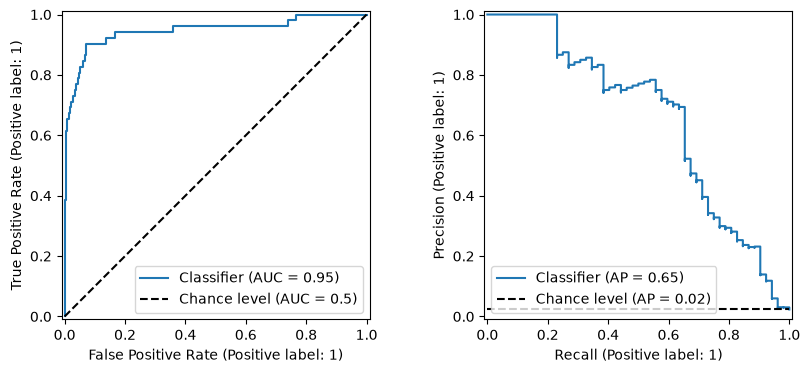

FPR <= 0.01: best recall 0.654
FPR <= 0.05: best recall 0.808
FPR <= 0.10: best recall 0.904
recall >= 0.5: best precision 0.784
recall >= 0.8: best precision 0.294
recall >= 0.9: best precision 0.232


In [6]:
import matplotlib.pyplot as plt
from sklearn.metrics import PrecisionRecallDisplay, RocCurveDisplay, precision_recall_curve, roc_curve

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
RocCurveDisplay.from_predictions(y_val, p_val, ax=ax1, plot_chance_level=True)
PrecisionRecallDisplay.from_predictions(y_val, p_val, ax=ax2, plot_chance_level=True)
plt.show()

fpr, tpr, _ = roc_curve(y_val, p_val)
for max_fpr in [0.01, 0.05, 0.10]:
    print(f"FPR <= {max_fpr:.2f}: best recall {tpr[fpr <= max_fpr].max():.3f}")
prec, rec, _ = precision_recall_curve(y_val, p_val)
for min_rec in [0.5, 0.8, 0.9]:
    print(f"recall >= {min_rec:.1f}: best precision {prec[rec >= min_rec].max():.3f}")

**Resposta.** Mais perto de 0,3: a melhor precisão com recall ≥ 0,8 é 0,294, contra 0,784 em recall 0,5 e 0,232 em recall 0,9. Pela ROC, recall 0,808 exige FPR de até 5%, e 5% das cerca de 2.185 regiões benignas ainda são umas 100 regiões, mais que o dobro dos 42 malignos encontrados.

**Simulação: o preço de cada ponto de recall.** Para metas de recall de 0,50 a 0,95, encontre na validação o limiar que atinge a meta com a melhor precisão e conte quantas regiões ele sinaliza. Traduza a precisão em algo que um radiologista entenda: quantas regiões benignas ele revisa para cada câncer encontrado?

In [7]:
prec, rec, thr = precision_recall_curve(y_val, p_val)
rows = []
for target in [0.50, 0.60, 0.70, 0.80, 0.90, 0.95]:
    ok = rec[:-1] >= target                              # limiares que atingem a meta
    i = np.argmax(np.where(ok, prec[:-1], -1))           # entre eles, a melhor precisão
    rows.append({'recall target': target, 'threshold': thr[i], 'recall': rec[i], 'precision': prec[i],
                 'flagged': (p_val >= thr[i]).sum(), 'benign per cancer': (1 - prec[i]) / prec[i]})
print(pd.DataFrame(rows).round(4).to_string(index=False))

 recall target  threshold  recall  precision  flagged  benign per cancer
          0.50     0.3651  0.5577     0.7838       37             0.2759
          0.60     0.2907  0.6154     0.7111       45             0.4062
          0.70     0.1085  0.7115     0.4512       82             1.2162
          0.80     0.0632  0.8077     0.2937      143             2.4048
          0.90     0.0425  0.9038     0.2315      203             3.3191
          0.95     0.0050  0.9615     0.0599      835            15.7000


**Leitura.** Recall 0,50 sai com limiar 0,365, 37 regiões sinalizadas e 0,28 benigna revisada por câncer encontrado; recall 0,80 pede limiar 0,063, 143 regiões e 2,4 benignas por câncer; 0,90 pede 0,043, 203 regiões e 3,3; e 0,95 pede 0,005, 835 regiões e 15,7 benignas por câncer. O preço de cada ponto de recall cresce muito no fim da curva, e todos os limiares úteis ficam muito abaixo de 0,5.

**Para fechar a parte fundamental.** Em uma frase cada: (1) por que a curva ROC não muda quando a doença fica mais rara e a curva PR muda? (2) O que a AUC mede que a acurácia em 0,5 não mede? (3) Quem decide o ponto de operação, o treino ou você?

**Resposta.**
1. A ROC usa taxas calculadas dentro de cada classe (recall nos malignos, FPR nos benignos), que não dependem da proporção entre elas; a precisão mistura as duas classes e cai quando há mais benignos para gerar falsos positivos.
2. A AUC mede a qualidade da ordenação em todos os limiares (a chance de um maligno receber escore maior que um benigno), enquanto a acurácia em 0,5 olha um só ponto, dominado pela classe majoritária (0,9839 contra 0,9768 do baseline).
3. Você: o treino entrega os escores, e o ponto de operação é escolhido na validação a partir de uma meta (recall 0,80) ou de custos.

## Sua vez (fundamental)

Para casa:

1. **A escada à mão.** Pegue os 10 primeiros pacientes do exemplo das 20 linhas e desenhe a curva ROC deles no papel, um degrau por paciente. Confira com `roc_curve`. Em que ponto está o limiar 0,5?
2. **AUC sem calibração.** Comprima os escores da validação do passo 4 para a faixa de 0,40 a 0,41 com `0.40 + 0.01 * p_val`. O que acontece com a AUC e o que acontece com a acurácia em 0,5? Que métrica você usaria para descobrir que as probabilidades estão erradas?
3. **AP contra a linha de base.** Calcule a AP de um escorador aleatório (use `rng.random(len(y_val))`) e compare com a AP do modelo e com a prevalência. Quantas vezes melhor que o acaso o modelo é?

## Passo 6 — pesos de classe

**Preveja.** Com `class_weight='balanced'`, o que você espera que mude mais: a ROC AUC (a ordenação) ou o número de regiões sinalizadas em 0,5?

In [8]:
lr_w = make_pipeline(StandardScaler(), LogisticRegression(class_weight='balanced')).fit(X_train, y_train)
p_val_w = lr_w.predict_proba(X_val)[:, 1]
pred = (p_val_w >= 0.5).astype(int)
print(f"flagged {pred.sum()}   recall {recall_score(y_val, pred):.3f}   precision {precision_score(y_val, pred):.3f}")
print(f"ROC AUC {roc_auc_score(y_val, p_val_w):.3f}   AP {average_precision_score(y_val, p_val_w):.3f}")
n0, n1 = np.bincount(y_train)
print(f"intercept shift {lr_w[-1].intercept_[0] - lr[-1].intercept_[0]:.2f}   log(n0/n1) = {np.log(n0 / n1):.2f}")

flagged 298   recall 0.904   precision 0.158
ROC AUC 0.954   AP 0.641
intercept shift 4.04   log(n0/n1) = 3.74


**Resposta.** Muda muito mais o número de regiões sinalizadas: de 30 para 298 em 0,5 (recall 0,904, precisão 0,158), enquanto a ROC AUC quase não se mexe (0,946 → 0,954) e a AP até cai (0,653 → 0,641). O intercepto sobe 4,04, perto de log(n0/n1) = 3,74: os pesos basicamente deslocam o ponto de corte.

**Simulação: o limiar que imita os pesos.** Se os pesos basicamente deslocam o ponto de operação, dá para chegar perto sem retreinar: corte os escores do modelo **simples** na prevalência do treino em vez de em 0,5. Compare esse ponto com o do modelo com pesos em 0,5 e conte em quantas regiões as duas regras discordam.

In [9]:
t_prev = y_train.mean()                                  # prevalência do treino
pred_prev = (p_val >= t_prev).astype(int)                # modelo simples, cortado na prevalência
pred_w = (p_val_w >= 0.5).astype(int)                    # modelo com pesos, cortado em 0,5
for name, pr in [(f'simple @ {t_prev:.4f}', pred_prev), ('balanced @ 0.5', pred_w)]:
    print(f"{name:17s} flagged {pr.sum()}   recall {recall_score(y_val, pr):.3f}"
          f"   precision {precision_score(y_val, pr):.3f}")
print(f"the two rules disagree on {(pred_prev != pred_w).sum()} of {len(y_val)} regions")

simple @ 0.0233   flagged 366   recall 0.923   precision 0.131
balanced @ 0.5    flagged 298   recall 0.904   precision 0.158
the two rules disagree on 110 of 2237 regions


**Leitura.** Cortar o modelo simples na prevalência do treino (0,0233) sinaliza 366 regiões, com recall 0,923 e precisão 0,131, perto do modelo com pesos em 0,5 (298 regiões, 0,904 e 0,158). As duas regras discordam em 110 das 2.237 regiões (4,9%): a aproximação é razoável, mas não exata, porque os pesos também mudam um pouco os coeficientes, não só o intercepto.

## Passo 7 — reamostragem dentro de um pipeline do `imblearn`

**Preveja.** A subamostragem vai treinar em quantas linhas, mais ou menos? E o SMOTE? Qual das duas joga informação fora?

In [10]:
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import make_pipeline as make_imb_pipeline
from imblearn.under_sampling import RandomUnderSampler

models = {
    'logistic': lr,
    'logistic, balanced': lr_w,
    'undersampling': make_imb_pipeline(StandardScaler(), RandomUnderSampler(random_state=0),
                                       LogisticRegression()),
    'SMOTE': make_imb_pipeline(StandardScaler(), SMOTE(random_state=0), LogisticRegression()),
}
for name in ['undersampling', 'SMOTE']:
    models[name].fit(X_train, y_train)            # o amostrador roda aqui, só no X_train
    X_r, y_r = models[name][1].fit_resample(X_train, y_train)
    print(f"{name:14s} trains on {len(y_r):5d} rows, {y_r.sum():4d} malignant")

undersampling  trains on   312 rows,  156 malignant
SMOTE          trains on 13106 rows, 6553 malignant


**Resposta.** A subamostragem treina em 312 linhas (as 156 malignas e 156 benignas sorteadas), jogando fora cerca de 6.400 benignas; o SMOTE treina em 13.106 linhas, com 6.553 malignas, das quais 6.397 são sintéticas. Só a subamostragem descarta informação; o SMOTE inventa pontos.

## Passo 8 — comparar no conjunto de validação

**Preveja.** Entre os quatro modelos, qual você espera que tenha a melhor ordenação (ROC AUC e AP)? A diferença vai ser grande?

In [11]:
from sklearn.metrics import f1_score

rows = []
for name, model in models.items():
    p = model.predict_proba(X_val)[:, 1]
    f = p >= 0.5
    rows.append({'model': name, 'ROC AUC': roc_auc_score(y_val, p), 'AP': average_precision_score(y_val, p),
                 'precision@0.5': precision_score(y_val, f), 'recall@0.5': recall_score(y_val, f),
                 'F1@0.5': f1_score(y_val, f)})
comparison = pd.DataFrame(rows).set_index('model')
print(comparison.round(3).to_string())

                    ROC AUC     AP  precision@0.5  recall@0.5  F1@0.5
model                                                                
logistic              0.946  0.653          0.767       0.442   0.561
logistic, balanced    0.954  0.641          0.158       0.904   0.269
undersampling         0.941  0.622          0.146       0.904   0.251
SMOTE                 0.955  0.647          0.164       0.885   0.276

**Resposta.** As ordenações são muito próximas: ROC AUC entre 0,941 e 0,955 e AP entre 0,622 e 0,653, com a logística simples na melhor AP (0,653) e o SMOTE na melhor ROC AUC (0,955). As grandes diferenças aparecem só no corte em 0,5 (recall 0,442 contra 0,885 a 0,904), que reflete a escala dos escores, não a qualidade.

**Simulação: comparar no limiar justo.** A tabela acima corta os quatro modelos em 0,5, o que é injusto: cada um põe seus escores numa escala diferente. Refaça a comparação dando a **cada modelo o seu próprio limiar**, o que atinge recall ≥ 0,80 na validação com a melhor precisão. As diferenças aumentam ou diminuem?

In [12]:
def threshold_for_recall(y_true, p, target=0.80):
    """Limiar que atinge recall >= target com a melhor precisão."""
    prec, rec, thr = precision_recall_curve(y_true, p)
    i = np.argmax(np.where(rec[:-1] >= target, prec[:-1], -1))
    return thr[i], rec[i], prec[i]

rows = []
for name, model in models.items():
    p = model.predict_proba(X_val)[:, 1]
    t, r, pr = threshold_for_recall(y_val, p)
    rows.append({'model': name, 'threshold': t, 'recall': r, 'precision': pr, 'flagged': (p >= t).sum()})
print(pd.DataFrame(rows).set_index('model').round(4).to_string())

                    threshold  recall  precision  flagged
model                                                    
logistic               0.0632  0.8077     0.2937      143
logistic, balanced     0.6026  0.8077     0.2111      199
undersampling          0.6433  0.8077     0.2059      204
SMOTE                  0.6379  0.8077     0.2545      165


**Leitura.** Com todos em recall 0,808, a logística simples tem a melhor precisão (0,294, 143 regiões), seguida do SMOTE (0,255, 165), dos pesos (0,211, 199) e da subamostragem (0,206, 204). As diferenças diminuem em relação ao corte em 0,5 (precisões de 0,146 a 0,767) e a leitura se inverte: rebalancear não trouxe ganho nenhum. Os limiares vão de 0,063 a 0,643, cada modelo na sua escala.

## Passo 9 — escolher o modelo e o limiar na validação

**Preveja.** Dado o que o passo 8 mostrou, qual modelo deve ser escolhido? E o limiar que atinge recall 0,80 vai ficar perto de 0,5 ou bem abaixo?

In [13]:
best_name = comparison['AP'].idxmax()
best = models[best_name]
p_val_best = best.predict_proba(X_val)[:, 1]
prec, rec, thr = precision_recall_curve(y_val, p_val_best)
ok = rec[:-1] >= 0.80                            # limiares que atingem a meta de recall
i = np.argmax(np.where(ok, prec[:-1], -1))       # entre eles, a melhor precisão
threshold = thr[i]
print(f"model: {best_name}   threshold {threshold:.4f}")
print(f"validation: recall {rec[i]:.3f}   precision {prec[i]:.3f}   flagged {(p_val_best >= threshold).sum()}")

model: logistic   threshold 0.0632
validation: recall 0.808   precision 0.294   flagged 143


**Resposta.** A logística simples, que tem a melhor AP (0,653). O limiar que atinge recall 0,80 fica bem abaixo de 0,5: 0,0632, com recall 0,808, precisão 0,294 e 143 regiões sinalizadas.

## Passo 10 — o único teste

**Preveja.** O recall no teste vai ficar acima ou abaixo dos 0,808 da validação? Com 52 casos malignos, quanto vale um caso?

In [14]:
from sklearn.metrics import confusion_matrix

p_test = best.predict_proba(X_test)[:, 1]
pred_test = (p_test >= threshold).astype(int)
print(confusion_matrix(y_test, pred_test, labels=[1, 0]))
print(f"recall {recall_score(y_test, pred_test):.3f}   precision {precision_score(y_test, pred_test):.3f}"
      f"   flagged {pred_test.sum()} of {len(pred_test)}")
print(f"ROC AUC {roc_auc_score(y_test, p_test):.3f}   AP {average_precision_score(y_test, p_test):.3f}")

[[  43    9]
 [  97 2088]]
recall 0.827   precision 0.307   flagged 140 of 2237
ROC AUC 0.913   AP 0.644


**Resposta.** Ficou um pouco acima: 0,827 (43 de 52) contra 0,808 na validação, com precisão 0,307 e 140 regiões sinalizadas. A diferença é de um caso (1/52 ≈ 0,019), dentro do ruído; já a ROC AUC no teste caiu para 0,913 (0,946 na validação), com AP 0,644.

## Passo 11 — a escada grosseira de um k-NN

**Preveja.** Com $k = 5$, quantas probabilidades distintas o k-NN pode produzir? Quantos pontos a curva ROC dele vai ter e isso é um problema para a nossa meta de recall 0,80?

distinct probabilities: [0.  0.2 0.4 0.6 0.8 1. ]
ROC points: 7   ROC AUC 0.935   AP 0.670
threshold inf   FPR 0.000   recall 0.000
threshold 1.0   FPR 0.001   recall 0.308
threshold 0.8   FPR 0.002   recall 0.481
threshold 0.6   FPR 0.004   recall 0.558
threshold 0.4   FPR 0.007   recall 0.750
threshold 0.2   FPR 0.038   recall 0.885
threshold 0.0   FPR 1.000   recall 1.000


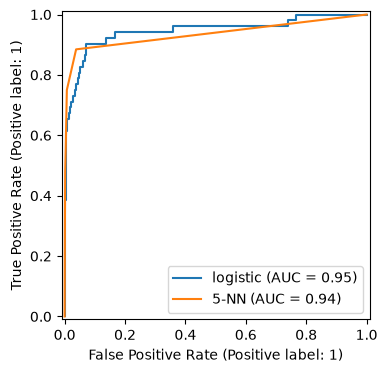

In [15]:
from sklearn.neighbors import KNeighborsClassifier

knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)).fit(X_train, y_train)
p_knn = knn.predict_proba(X_val)[:, 1]
print("distinct probabilities:", np.unique(p_knn))
fpr_k, tpr_k, thr_k = roc_curve(y_val, p_knn)
print(f"ROC points: {len(thr_k)}   ROC AUC {roc_auc_score(y_val, p_knn):.3f}   AP {average_precision_score(y_val, p_knn):.3f}")
for t, f, r in zip(thr_k, fpr_k, tpr_k):
    print(f"threshold {t:.1f}   FPR {f:.3f}   recall {r:.3f}")

fig, ax = plt.subplots(figsize=(5, 4))
RocCurveDisplay.from_predictions(y_val, p_val, ax=ax, name='logistic')
RocCurveDisplay.from_predictions(y_val, p_knn, ax=ax, name='5-NN')
plt.show()

**Resposta.** No máximo 6 probabilidades (0; 0,2; ...; 1), então a curva ROC tem 7 pontos contando o limiar infinito. É um problema para a meta: nenhum ponto cai em recall 0,80, e os vizinhos são 0,750 (limiar 0,4, FPR 0,007) e 0,885 (limiar 0,2, FPR 0,038). Mesmo assim a ROC AUC é 0,935 e a AP 0,670.

**Para fechar a aula.** Em uma frase cada: (1) o que os pesos de classe mudaram e o que não mudaram? (2) Por que reamostrar antes de dividir inflaciona o resultado de duas maneiras? (3) Por que a regressão logística simples venceu a comparação?

**Resposta.**
1. Os pesos mudaram a escala dos escores e, com ela, o que o corte em 0,5 sinaliza (30 → 298 regiões, intercepto +4,04), mas não a ordenação (ROC AUC 0,946 → 0,954, AP 0,653 → 0,641).
2. Porque os pontos sintéticos que caem no teste são interpolações de vizinhos que estão no treino (vazamento: o modelo reconhece quase-cópias) e porque o teste fica com 50% de malignos em vez de 2,3%, o que infla a precisão; no exercício 2 avançado isso deu recall e precisão de 0,963.
3. Porque, com cada modelo no seu limiar, a reamostragem só desloca um ponto de corte que o limiar já ajusta, e a logística simples tinha a melhor ordenação na região de recall alto (AP 0,653, precisão 0,294 em recall 0,808) sem descartar dados nem inventar pontos.

## Sua vez (avançado)

Para casa, com mais tempo:

1. **Um custo em vez de uma meta.** Suponha que deixar passar um câncer custe 20 vezes uma nova convocação desnecessária. No conjunto de validação, calcule o custo $20 \cdot FN + FP$ para cada limiar do modelo escolhido e encontre o mínimo. Compare com a fórmula $t^* = 1/(1+20)$. Por que eles diferem?
2. **Reamostrar antes de dividir.** Aplique `SMOTE` a todo o `X, y`, depois divida 80/20 e ajuste um 5-NN. Compare seu recall e sua precisão com o passo 10. Quais duas coisas deram errado?
3. **Mais vizinhos.** Repita o passo 11 com $k = 15$ e $k = 51$. Quantas probabilidades distintas, quantos pontos ROC e o que acontece com a AUC? Quais pontos de operação perto de recall 0,80 passam a existir?
4. **A sorte da divisão.** Troque `random_state=7` no passo 2 por 0, 1, 2, 3 e 4 e rode de novo os passos 2–10. Quanto se movem o limiar escolhido e o recall de teste? O que isso diz sobre reportar "recall 0,827" com três casas decimais?

## Sua vez (fundamental) — exercícios

### Sua vez — exercício 1 (fundamental): a escada à mão

 threshold  FPR hand  FPR sklearn  TPR hand  TPR sklearn
       inf       0.0          0.0     0.000        0.000
      0.95       0.0          0.0     0.125        0.125
      0.90       0.0          0.0     0.250        0.250
      0.85       0.0          0.0     0.375        0.375
      0.80       0.0          0.0     0.500        0.500
      0.75       0.5          0.5     0.500        0.500
      0.70       0.5          0.5     0.625        0.625
      0.65       0.5          0.5     0.750        0.750
      0.60       1.0          1.0     0.750        0.750
      0.55       1.0          1.0     0.875        0.875
      0.45       1.0          1.0     1.000        1.000
same curve: True   AUC 0.625
threshold 0.5: FPR 1.000   TPR 0.875


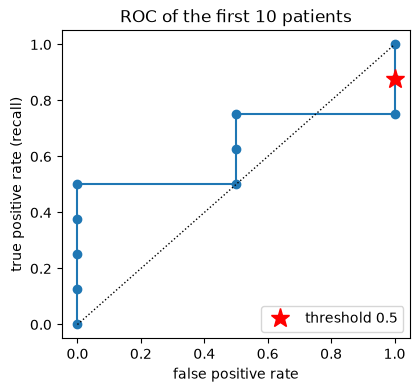

In [16]:
# os 10 primeiros pacientes do exemplo das 20 linhas da página da aula
score10 = np.array([0.95, 0.90, 0.85, 0.80, 0.75, 0.70, 0.65, 0.60, 0.55, 0.45])
sick10 = np.array([1, 1, 1, 1, 0, 1, 1, 0, 1, 1])

# à mão: descendo pelos escores, cada doente sobe um degrau, cada saudável anda para a direita
tpr_hand = np.r_[0, np.cumsum(sick10) / sick10.sum()]
fpr_hand = np.r_[0, np.cumsum(1 - sick10) / (1 - sick10).sum()]
fpr10, tpr10, thr10 = roc_curve(sick10, score10, drop_intermediate=False)
print(pd.DataFrame({'threshold': thr10, 'FPR hand': fpr_hand, 'FPR sklearn': fpr10,
                    'TPR hand': tpr_hand, 'TPR sklearn': tpr10}).round(3).to_string(index=False))
print("same curve:", np.allclose(fpr_hand, fpr10) and np.allclose(tpr_hand, tpr10),
      f"  AUC {roc_auc_score(sick10, score10):.3f}")
at05 = score10 >= 0.5
print(f"threshold 0.5: FPR {at05[sick10 == 0].mean():.3f}   TPR {at05[sick10 == 1].mean():.3f}")

fig, ax = plt.subplots(figsize=(4.5, 4))
ax.step(fpr10, tpr10, where='post', marker='o')
ax.plot(at05[sick10 == 0].mean(), at05[sick10 == 1].mean(), 'r*', ms=14, label='threshold 0.5')
ax.plot([0, 1], [0, 1], 'k:', lw=1)
ax.set_xlabel('false positive rate')
ax.set_ylabel('true positive rate (recall)')
ax.set_title('ROC of the first 10 patients')
ax.legend(loc='lower right')
plt.show()

**Conclusão.** Descendo pelos escores, os quatro primeiros doentes sobem a escada até TPR 0,5, P05 (saudável) anda até FPR 0,5, P06 e P07 sobem a 0,75, P08 anda até FPR 1,0, e P09 e P10 levam a TPR 1,0. O `roc_curve` devolve exatamente os mesmos 11 pontos (AUC 0,625). O limiar 0,5 sinaliza os nove primeiros e fica no ponto (FPR 1,0, TPR 0,875): só P10 (0,45) fica abaixo.

### Sua vez — exercício 2 (fundamental): AUC sem calibração

In [17]:
from sklearn.metrics import brier_score_loss, log_loss

p_squash = 0.40 + 0.01 * p_val                           # mesma ordem, escala absurda
for name, s in [('p_val', p_val), ('0.40 + 0.01 p', p_squash)]:
    print(f"{name:14s} ROC AUC {roc_auc_score(y_val, s):.3f}   AP {average_precision_score(y_val, s):.3f}"
          f"   accuracy@0.5 {accuracy_score(y_val, s >= 0.5):.4f}   flagged {(s >= 0.5).sum():3d}"
          f"   log loss {log_loss(y_val, s):.3f}   Brier {brier_score_loss(y_val, s):.4f}")

p_val          ROC AUC 0.946   AP 0.653   accuracy@0.5 0.9839   flagged  30   log loss 0.051   Brier 0.0125
0.40 + 0.01 p  ROC AUC 0.946   AP 0.653   accuracy@0.5 0.9768   flagged   0   log loss 0.520   Brier 0.1646


**Conclusão.** A AUC (0,946) e a AP (0,653) não mudam, porque a ordem é a mesma; a acurácia em 0,5 cai de 0,9839 para 0,9768, porque nenhuma região passa de 0,41 e o modelo vira o baseline que nunca sinaliza. Para descobrir que as probabilidades estão erradas, use uma métrica de probabilidade: a log loss sobe de 0,051 para 0,520 e o Brier de 0,0125 para 0,1646 (uma curva de calibração mostraria o mesmo).

### Sua vez — exercício 3 (fundamental): AP contra a linha de base

In [18]:
rng = np.random.default_rng(42)
ap_random = average_precision_score(y_val, rng.random(len(y_val)))
ap_many = [average_precision_score(y_val, rng.random(len(y_val))) for _ in range(200)]
ap_model = average_precision_score(y_val, p_val)
print(f"prevalence {y_val.mean():.4f}   AP random (1 draw) {ap_random:.4f}"
      f"   AP random (mean of 200) {np.mean(ap_many):.4f}")
print(f"AP model {ap_model:.3f}   = {ap_model / y_val.mean():.1f}x the prevalence")

prevalence 0.0232   AP random (1 draw) 0.0224   AP random (mean of 200) 0.0270
AP model 0.653   = 28.1x the prevalence


**Conclusão.** Um escorador aleatório tem AP 0,0224 (média de 200 sorteios 0,0270, um pouco acima pelo ruído de só 52 positivos), praticamente a prevalência de 0,0232. O modelo, com AP 0,653, é cerca de 28 vezes melhor que o acaso (0,653 / 0,0232 = 28,1).

## Sua vez (avançado) — exercícios

### Sua vez — exercício 1 (avançado): um custo em vez de uma meta

empirical minimum: threshold 0.0425   FN 5   FP 156   cost 256
formula t* = 1/21 = 0.0476:   FN 8   FP 139   cost 299
step 9 threshold 0.0632:   FN 10   FP 101   cost 301


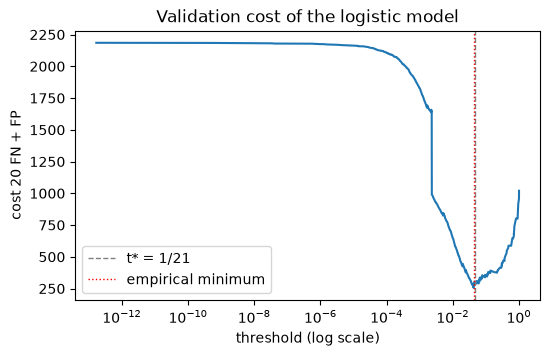

In [19]:
fpr_b, tpr_b, thr_b = roc_curve(y_val, p_val_best, drop_intermediate=False)
n_pos, n_neg = y_val.sum(), (y_val == 0).sum()
fn_b, fp_b = np.round((1 - tpr_b) * n_pos), np.round(fpr_b * n_neg)
cost = 20 * fn_b + fp_b
j = np.argmin(cost[1:]) + 1                              # ignora o limiar infinito
t_star = 1 / (1 + 20)
pred_star = p_val_best >= t_star
fn_s, fp_s = ((y_val == 1) & ~pred_star).sum(), ((y_val == 0) & pred_star).sum()
print(f"empirical minimum: threshold {thr_b[j]:.4f}   FN {fn_b[j]:.0f}   FP {fp_b[j]:.0f}   cost {cost[j]:.0f}")
print(f"formula t* = 1/21 = {t_star:.4f}:   FN {fn_s}   FP {fp_s}   cost {20 * fn_s + fp_s}")
pred_80 = p_val_best >= threshold
fn_80, fp_80 = ((y_val == 1) & ~pred_80).sum(), ((y_val == 0) & pred_80).sum()
print(f"step 9 threshold {threshold:.4f}:   FN {fn_80}   FP {fp_80}   cost {20 * fn_80 + fp_80}")

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(thr_b[1:], cost[1:])
ax.axvline(t_star, color='gray', ls='--', lw=1, label='t* = 1/21')
ax.axvline(thr_b[j], color='red', ls=':', lw=1, label='empirical minimum')
ax.set_xscale('log')
ax.set_xlabel('threshold (log scale)')
ax.set_ylabel('cost 20 FN + FP')
ax.set_title(f'Validation cost of the {best_name} model')
ax.legend()
plt.show()

**Conclusão.** O mínimo empírico do custo 20·FN + FP na validação fica no limiar 0,0425 (5 FN, 156 FP, custo 256); a fórmula $t^* = 1/21 = 0,0476$ dá 8 FN e 139 FP, custo 299, e o limiar 0,0632 do passo 9 custa 301. Eles diferem porque a fórmula supõe probabilidades calibradas, o que a logística não garante nessa faixa de escores tão baixos; além disso, com 52 malignos cada FN vale 20 e o mínimo empírico pula conforme dois ou três casos, ou seja, também se ajusta ao ruído da validação.

### Sua vez — exercício 2 (avançado): reamostrar antes de dividir

In [20]:
X_sm, y_sm = SMOTE(random_state=42).fit_resample(X, y)   # errado de propósito: SMOTE antes da divisão
Xs_train, Xs_test, ys_train, ys_test = train_test_split(X_sm, y_sm, test_size=0.2, stratify=y_sm,
                                                        random_state=42)
knn_leak = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)).fit(Xs_train, ys_train)
pred_leak = knn_leak.predict(Xs_test)
synthetic = Xs_test.index >= len(X)                      # o SMOTE anexa os sintéticos depois das linhas reais
print(f"test: {len(ys_test)} rows, {ys_test.mean():.1%} malignant, {synthetic.sum()} of them synthetic")
print(f"leaky 5-NN:  recall {recall_score(ys_test, pred_leak):.3f}   precision {precision_score(ys_test, pred_leak):.3f}")
print(f"step 10:     recall {recall_score(y_test, pred_test):.3f}   precision {precision_score(y_test, pred_test):.3f}")

test: 4370 rows, 50.0% malignant, 2138 of them synthetic
leaky 5-NN:  recall 0.963   precision 0.963
step 10:     recall 0.827   precision 0.307


**Conclusão.** O 5-NN "vazado" tem recall e precisão de 0,963, muito acima dos 0,827 e 0,307 do passo 10, mas o número é falso. Duas coisas deram errado: (1) vazamento: 2.138 das 4.370 linhas de teste são sintéticas, interpoladas entre malignos que estão no treino, e o 5-NN encontra quase-cópias delas; (2) prevalência: o teste tem 50% de malignos em vez de 2,3%, o que infla a precisão e não representa as mamografias reais.

### Sua vez — exercício 3 (avançado): mais vizinhos

In [21]:
for k in [5, 15, 51]:
    knn_k = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k)).fit(X_train, y_train)
    p = knn_k.predict_proba(X_val)[:, 1]
    fpr_k, tpr_k, thr_k = roc_curve(y_val, p)
    print(f"k = {k:2d}   distinct {len(np.unique(p)):2d}   ROC points {len(thr_k):2d}"
          f"   ROC AUC {roc_auc_score(y_val, p):.3f}   AP {average_precision_score(y_val, p):.3f}")
    near = (tpr_k >= 0.70) & (tpr_k <= 0.90)              # pontos de operação perto de recall 0,80
    for t, f, r in zip(thr_k[near], fpr_k[near], tpr_k[near]):
        print(f"     threshold {t:.3f}   FPR {f:.3f}   recall {r:.3f}   flagged {(p >= t).sum()}")

k =  5   distinct  6   ROC points  7   ROC AUC 0.935   AP 0.670
     threshold 0.400   FPR 0.007   recall 0.750   flagged 55
     threshold 0.200   FPR 0.038   recall 0.885   flagged 129
k = 15   distinct 15   ROC points 16   ROC AUC 0.941   AP 0.671
     threshold 0.200   FPR 0.010   recall 0.731   flagged 60
     threshold 0.133   FPR 0.021   recall 0.846   flagged 90


k = 51   distinct 34   ROC points 30   ROC AUC 0.937   AP 0.670


     threshold 0.118   FPR 0.016   recall 0.788   flagged 76
     threshold 0.098   FPR 0.023   recall 0.846   flagged 95
     threshold 0.078   FPR 0.033   recall 0.885   flagged 118
     threshold 0.059   FPR 0.044   recall 0.885   flagged 143
     threshold 0.039   FPR 0.071   recall 0.885   flagged 202


**Conclusão.** Com k = 5 há 6 probabilidades e 7 pontos ROC (AUC 0,935); com k = 15, 15 valores e 16 pontos (AUC 0,941); com k = 51, 34 valores e 30 pontos, porque o `roc_curve` descarta pontos colineares (AUC 0,937). A AUC melhora um pouco e volta, e a AP fica em torno de 0,67. Perto de recall 0,80, k = 5 só oferece 0,750 ou 0,885; k = 15 traz 0,846 com FPR 0,021 (90 regiões); k = 51 traz 0,788 (76 regiões) e 0,846 (95), uma escada fina o bastante para escolher o ponto de operação.

### Sua vez — exercício 4 (avançado): a sorte da divisão

In [22]:
from sklearn.base import clone

rows = []
for seed in [7, 0, 1, 2, 3, 4]:
    Xt, Xte, yt, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=seed)
    Xtr, Xv, ytr, yv = train_test_split(Xt, yt, test_size=0.25, stratify=yt, random_state=seed)
    fitted = {name: clone(m).fit(Xtr, ytr) for name, m in models.items()}          # passos 4-7
    ap = {name: average_precision_score(yv, m.predict_proba(Xv)[:, 1]) for name, m in fitted.items()}
    chosen = max(ap, key=ap.get)                                                     # passos 8-9
    t, r, pr = threshold_for_recall(yv, fitted[chosen].predict_proba(Xv)[:, 1])
    pt = fitted[chosen].predict_proba(Xte)[:, 1] >= t                                # passo 10
    rows.append({'seed': seed, 'model': chosen, 'threshold': t, 'val recall': r, 'val precision': pr,
                 'test recall': recall_score(yte, pt), 'test precision': precision_score(yte, pt),
                 'test malignant': yte.sum()})
luck = pd.DataFrame(rows)
print(luck.round(3).to_string(index=False))
print(f"test recall: min {luck['test recall'].min():.3f}   max {luck['test recall'].max():.3f}"
      f"   std {luck['test recall'].std():.3f}   (one case = {1 / 52:.3f})")

 seed    model  threshold  val recall  val precision  test recall  test precision  test malignant
    7 logistic      0.063       0.808          0.294        0.827           0.307              52
    0 logistic      0.102       0.808          0.442        0.692           0.474              52
    1 logistic      0.078       0.808          0.331        0.769           0.354              52
    2 logistic      0.070       0.808          0.326        0.654           0.324              52
    3 logistic      0.084       0.808          0.400        0.635           0.320              52
    4 logistic      0.068       0.808          0.356        0.788           0.315              52
test recall: min 0.635   max 0.827   std 0.078   (one case = 0.019)


**Conclusão.** Nas seis divisões a logística simples vence pela AP, mas o limiar escolhido vai de 0,063 a 0,102 e o recall de teste de 0,635 a 0,827 (desvio-padrão 0,078, cerca de 4 casos de 52); a precisão de teste vai de 0,307 a 0,474. Na validação o recall é sempre 0,808 por construção, mas no teste ele oscila quase 20 pontos: reportar "recall 0,827" com três casas sugere uma precisão que não existe; o honesto é dar uma faixa (algo como 0,65 a 0,83) ou usar validação cruzada.